[*********************100%***********************]  1 of 1 completed


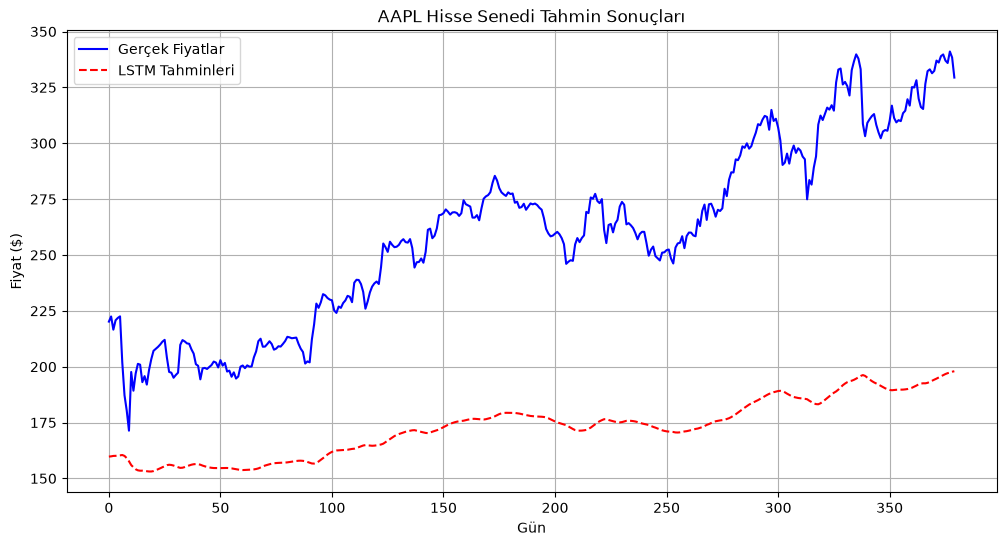

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler

ticker = "AAPL"
df = yf.download(ticker, start="2018-01-01", end="2026-09-30")
data = df[['Close']].values

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

train_size = int(len(scaled_data) * 0.8)
test_data = scaled_data[train_size:]

seq_length = 60
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        xs.append(data[i:(i + seq_length)])
        ys.append(data[i + seq_length])
    return np.array(xs), np.array(ys)

X_test, y_test = create_sequences(test_data, seq_length)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

class StockLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=50, num_layers=2):
        super(StockLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return out

model = StockLSTM()
model.load_state_dict(torch.load("lstm_stock_model.pth"))
model.eval()

with torch.no_grad():
    predictions = model(X_test_t).numpy()

predictions_actual = scaler.inverse_transform(predictions)
y_test_actual = scaler.inverse_transform(y_test)

plt.figure(figsize=(12, 6))
plt.plot(y_test_actual, label="Gerçek Fiyatlar", color="blue")
plt.plot(predictions_actual, label="LSTM Tahminleri", color="red", linestyle="--")
plt.title(f"{ticker} Hisse Senedi Tahmin Sonuçları")
plt.xlabel("Gün")
plt.ylabel("Fiyat ($)")
plt.legend()
plt.grid(True)
plt.show()